# 02 — Understand quality and coverage
Report observed coverage rather than equating millions of records with years of history.
This notebook records valid retail counts **by item and date**, so Notebook 06 can refit
item screening at each expanding-window cutoff. It does not globally delete sparse items.
Full-period summaries describe the dataset and must not be used to tune against test outcomes.

Rows: 5581612 Dates: 2025-01-01 00:00:00 to 2026-06-30 00:00:00
Invalid prices: 0
Duplicate keys: 0


,dtype,missing,unique
date,datetime64[ms],0,515
premise_code,int64,0,2556
item_code,int64,0,27
price,float64,0,2033
item,string,0,27
unit,string,0,3
project_group,string,0,7
premise,string,0,2527
state,string,0,16
district,string,0,169


,records
project_group,
Chicken,528201
Cooking Oil,42555
Eggs,946588
Flour,105562
Rice,43513
Sugar,124986
Vegetables,3790207


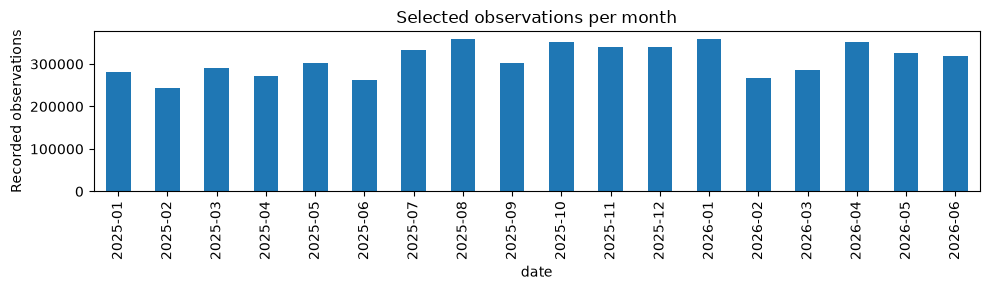

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Run from the repository root or its notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import numpy as np
import pricecatcher_config as cfg
from data_utils import save_json, surge_event
import matplotlib.pyplot as plt
from data_utils import item_screen
output = cfg.stage(2)
df = pd.read_parquet(cfg.stage(1) / "integrated.parquet")
df["date"] = pd.to_datetime(df["date"])
invalid = df["price"].isna() | ~np.isfinite(df["price"]) | df["price"].le(0)
print("Rows:", len(df), "Dates:", df["date"].min(), "to", df["date"].max())
print("Invalid prices:", int(invalid.sum()))
print("Duplicate keys:", int(df.duplicated(["date", "premise_code", "item_code"]).sum()))
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()}))
display(df.groupby("project_group").size().rename("records").to_frame())
monthly = df.groupby(df["date"].dt.to_period("M")).size()
monthly.plot.bar(figsize=(10, 3), title="Selected observations per month")
plt.ylabel("Recorded observations"); plt.tight_layout(); plt.show()


## Preserve counts needed for fold-specific screening
Only valid retail records contribute. An item is supported when its count is at least
5% of the median positive item count **inside the fold's training period**. This is a
transparent heuristic; inspect exclusions rather than claiming an economic standard.

In [2]:
retail = df.loc[~invalid].copy()
if cfg.REMOVE_BORONG:
    retail = retail.loc[retail["premise_type"].ne("Borong")]
if retail.empty:
    raise ValueError("No valid retail observations.")
counts = retail.groupby(["item_code", "date"]).size().rename("records").reset_index()
counts.to_parquet(output / "item_daily_counts.parquet", index=False)
screen = item_screen(counts, cfg.TRAIN_END)
screen.to_csv(output / "final_training_item_screen.csv", index=False)
display(screen)
# Days without observations anywhere in the selected basket, not missing shop prices.
calendar = pd.date_range(pd.Period(cfg.START_MONTH).start_time, pd.Period(cfg.END_MONTH).end_time.normalize())
missing_dates = calendar.difference(pd.DatetimeIndex(df["date"].unique()))
save_json(output / "quality_summary.json", {
    "rows": len(df), "invalid_prices": int(invalid.sum()),
    "distinct_dates": int(df["date"].nunique()), "missing_basket_dates": [str(x.date()) for x in missing_dates],
    "states": int(df["state"].nunique()),
    "state_district_pairs": int(df[["state", "district"]].drop_duplicates().shape[0]),
    "premises": int(df["premise_code"].nunique()),
})
print("Saved date-level counts for leakage-safe backtesting.")


,item_code,records,cutoff,include
0,1,268708,6314.4,True
1,2,80631,6314.4,True
2,93,126288,6314.4,True
3,94,221870,6314.4,True
4,104,256482,6314.4,True
5,105,160839,6314.4,True
6,113,348152,6314.4,True
7,114,344321,6314.4,True
8,118,21775,6314.4,True
9,119,27391,6314.4,True


Saved date-level counts for leakage-safe backtesting.
